# Digital Image Processing — Week 5 · Task 5

**Grup: Nmertgules ve Iliya**

HUMS X-ray veri setinin **ThreatsRGB** klasöründen beş renkli görüntü → tek kanallı gri → açıklanmış bir paletle yeniden renklendirme. Ödev ekranındaki `ThreadsRGB` ifadesine karşılık özgün depodaki klasör `ThreatsRGB` adındadır.

Kaggle toplu indirme adresi 404 döndüğünden veri seti sahibinin [özgün deposundan](https://github.com/ElifErarslan1/HUMS-X-ray-Dataset) alındı. Görüntüler ve dosya bazında URL/SHA256 kayıtları [assets/xray_sources.json](assets/xray_sources.json) içindedir. Özgün README akademik kullanıma izin verir; veri seti çift enerjili tarayıcıdan gelen görüntüleri ve sözde renkli RGB görüntülerini içerir.

**Palet seçimi:** Tekdüze sıralı Cividis paletini, ters gri değer üzerinde kullanıyoruz. Açık arka plan koyu mavi, daha koyu nesne bölgeleri sarıya yaklaşır. Amaç şekil ve yoğunluk farklarını tutarlı bir ölçekle görünür kılmaktır. Renk körlüğü açısından da uygun bir başlangıç tercihidir. Operatör başarısı bu ödevde insan deneyiyle ölçülmemiştir.

Bu palet bir malzeme sınıflandırması değildir. RGB'den griye geçişte kaybolan özgün renk/malzeme bilgisi tek gri değerden geri kazanılamaz. Sarı renk otomatik olarak tehdit anlamına gelmez.


In [1]:
from pathlib import Path
import sys, json
import cv2
import numpy as np
import matplotlib.pyplot as plt
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'week4/assets/rocket.jpg').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Repoyu bütünüyle indirin ve repo içinden çalıştırın.')
WEEK = ROOT/'week5'
OUT = WEEK/'results'
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(WEEK))
print('OpenCV:', cv2.__version__, '| NumPy:', np.__version__)


OpenCV: 5.0.0 | NumPy: 2.5.4


In [2]:
import hashlib
sources = json.loads((WEEK/'assets/xray_sources.json').read_text())
records = sources['images']
assert len(records)==5
palettes = []
report = []
for item in records:
    path = WEEK/'assets/xray'/item['file']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item['sha256']
    original = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if original is None: raise FileNotFoundError(path)
    gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
    recolored = cv2.applyColorMap(255-gray, cv2.COLORMAP_CIVIDIS)
    assert gray.ndim==2 and recolored.shape==original.shape
    assert recolored.dtype == np.uint8
    # Aynı gri değer her pikselde aynı palet rengine eşlenmeli.
    lut = cv2.applyColorMap(np.arange(256,dtype=np.uint8).reshape(256,1),cv2.COLORMAP_CIVIDIS)[:,0]
    assert np.array_equal(recolored, lut[255-gray])
    # Bu hata bir doğruluk puanı değil; renklendirmelerin farklı olduğunu gösterir.
    d = np.abs(original.astype(np.int16)-recolored.astype(np.int16))
    report.append({'file':item['file'], 'width':int(gray.shape[1]),'height':int(gray.shape[0]),
                   'gray_min':int(gray.min()),'gray_max':int(gray.max()),
                   'mean_absolute_color_difference':float(d.mean()),
                   'different_pixel_percent':float(100*np.any(d!=0,axis=-1).mean())})
    palettes.append((original,gray,recolored,item['file']))
print(json.dumps(report,indent=2))
(OUT/'task5_metrics.json').write_text(json.dumps(report,indent=2),encoding='utf-8')


[
  {
    "file": "image_0_1000.jpg",
    "width": 789,
    "height": 478,
    "gray_min": 26,
    "gray_max": 255,
    "mean_absolute_color_difference": 171.28687603077887,
    "different_pixel_percent": 100.0
  },
  {
    "file": "image_0_1054.jpg",
    "width": 151,
    "height": 429,
    "gray_min": 38,
    "gray_max": 254,
    "mean_absolute_color_difference": 182.8266053299166,
    "different_pixel_percent": 100.0
  },
  {
    "file": "image_0_1062.jpg",
    "width": 61,
    "height": 263,
    "gray_min": 74,
    "gray_max": 254,
    "mean_absolute_color_difference": 174.88437324689895,
    "different_pixel_percent": 100.0
  },
  {
    "file": "image_0_1071.jpg",
    "width": 149,
    "height": 266,
    "gray_min": 29,
    "gray_max": 254,
    "mean_absolute_color_difference": 191.40095204454087,
    "different_pixel_percent": 100.0
  },
  {
    "file": "image_0_1072.jpg",
    "width": 581,
    "height": 478,
    "gray_min": 10,
    "gray_max": 254,
    "mean_absolute_color_diffe

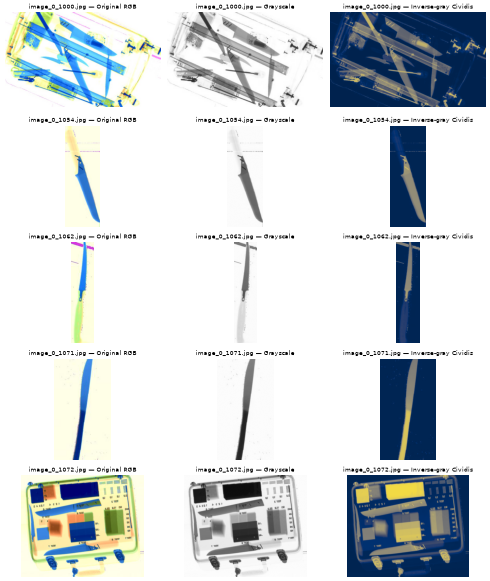

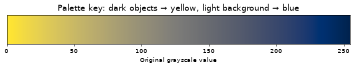

In [3]:
fig, axes = plt.subplots(5,3,figsize=(11,13))
for row,(original,gray,recolored,name) in enumerate(palettes):
    axes[row,0].imshow(cv2.cvtColor(original,cv2.COLOR_BGR2RGB))
    axes[row,1].imshow(gray,cmap='gray',vmin=0,vmax=255)
    axes[row,2].imshow(cv2.cvtColor(recolored,cv2.COLOR_BGR2RGB))
    for j,title in enumerate(['Original RGB','Grayscale','Inverse-gray Cividis']):
        axes[row,j].set_title(f'{name} — {title}',fontsize=9)
        axes[row,j].axis('off')
fig.tight_layout()
fig.savefig(OUT/'task5_comparison.png',dpi=100)
plt.show()
# Palet anahtarı: yatay eksen orijinal gri seviyedir.
scale = np.tile(np.arange(256,dtype=np.uint8),(20,1))
plt.figure(figsize=(8,1.6))
plt.imshow(cv2.cvtColor(cv2.applyColorMap(255-scale,cv2.COLORMAP_CIVIDIS),cv2.COLOR_BGR2RGB),extent=[0,255,0,1],aspect='auto')
plt.yticks([]);plt.xlabel('Original grayscale value');plt.title('Palette key: dark objects → yellow, light background → blue')
plt.tight_layout();plt.show()


## Beş görüntünün yorumu

- **image_0_1000.jpg:** Birden fazla üst üste nesne var. Renklendirme karanlık yapıların sınırlarını öne çıkarır; özgün mavi/turuncu ayrımlarını geri getirmez. Örtüşen nesneleri ayırdığı iddia edilmez.
- **image_0_1054.jpg:** Uzun bıçak benzeri yapı gri görüntüde de seçilir. Yeni palet koyu yapı ile açık arka planı farklı renklere taşır; nesne türü sınıflandırılmaz.
- **image_0_1062.jpg:** Dar ve uzun nesnenin silueti korunur. Düşük çözünürlükten kaynaklanan detay eksikliği renklendirmeyle giderilmez.
- **image_0_1071.jpg:** Kavisli uzun nesnede sınır/arka plan kontrastı renk koduyla gösterilir. Malzeme veya tehlike derecesi çıkarılmaz.
- **image_0_1072.jpg:** Elektronik bileşenler, bölmeler ve yoğunluk farkları seçilebilir. Özgün renklerin taşıyabildiği ek malzeme bilgisi griye geçişte kaybolmuştur.

**Orijinalle fark:** Orijinal sözde renkli RGB görüntünün aynı parlaklıktaki farklı renkleri griye çevrildiğinde aynı değere inebilir. Bu nedenle yeni renklendirme özgün RGB'nin kopyası değildir. Renk farkının yüksek olması bu görevin başarısız olduğu anlamına gelmez; amaç gri yapıyı farklı paletle göstermektir. Sayısal renk farkı yalnızca farkı raporlamak için verilmiştir, operatör performansı ölçümü değildir.
